# Programming for AI | E-commerce Product Analysis and Machine Learning
## Data Collection, Understanding, Cleaning, EDA, Skewness and Outliers

| Item | Detail |
|---|---|
| Instructor | Mahhek Tahir |
| Data source | Books to Scrape - https://books.toscrape.com/ |

## Section 1: Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, StandardScaler
from sklearn.ensemble import IsolationForest

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("pandas", pd.__version__)

pandas 3.0.6


**What was performed:** Imported the libraries (pandas/numpy for data, matplotlib/seaborn for plots, scipy for statistics, scikit-learn for encoding, scaling and Isolation Forest) and fixed `RANDOM_STATE = 42`.

## Section 2: Data Collection (Web Scraping Summary)

In [2]:
DATA_DIR = next((p for p in [Path("data"), Path("../data")] if (p / "books_raw.csv").exists()), None)
assert DATA_DIR is not None, "books_raw.csv not found. Run: python src/books_scraper.py"
RAW_FILE = DATA_DIR / "books_raw.csv"

raw = pd.read_csv(RAW_FILE, encoding="utf-8-sig")

print("Source file          :", RAW_FILE)
print("Records collected    :", len(raw))
print("Columns collected    :", raw.shape[1])
print("Unique product URLs  :", raw["product_url"].nunique())
print("Unique UPC codes     :", raw["UPC"].nunique())
print("Unique titles        :", raw["title"].nunique())

Source file          : ..\data\books_raw.csv
Records collected    : 1000
Columns collected    : 13
Unique product URLs  : 1000
Unique UPC codes     : 1000
Unique titles        : 999


**What was performed:** Loaded `books_raw.csv`, the output of `src/books_scraper.py`. The scraper (1) follows the catalogue *Next* links through every listing page, (2) collects each product URL, (3) visits every individual product page to extract title, price, star rating, availability and stock, category (from the breadcrumb), UPC, description, tax, price excl./incl. tax and number of reviews, (4) removes repeated product URLs, and (5) waits 0.4 seconds between requests with automatic retries, so the site is not overloaded.

**Why:** Listing pages do not contain UPC, description, category, stock or tax, so each product page must be visited. Responsible scraping (delay, retries, no duplicate requests) is required by the brief.

**What the output shows:**  Number of records collected = 1000, unique URLs = 1000, unique UPCs = 1000, unique titles =999.


In [3]:
field_report = pd.DataFrame({
    "non_null": raw.notna().sum(),
    "missing": raw.isna().sum(),
    "unique_values": raw.nunique(dropna=True),
})
field_report["constant_column"] = field_report["unique_values"] <= 1
field_report

,non_null,missing,unique_values,constant_column
title,1000,0,999,False
product_url,1000,0,1000,False
price,1000,0,903,False
star_rating,1000,0,5,False
availability_status,1000,0,1,True
stock_quantity,1000,0,21,False
category,1000,0,50,False
UPC,1000,0,1000,False
description,998,2,998,False
tax,1000,0,1,True


**What was performed:** Built a field-availability report: non-null count, missing count, number of unique values and a flag for columns that never change.

**Why:** The brief asks us to report fields that are unavailable or inconsistent. A constant column carries no information for any model and must be identified early.

**What the output shows:**  List the columns flagged `constant_column = True` (expected: `tax`, `number_of_reviews`, and probably `availability_status`) and any column with missing values (expected: possibly `description`).

**Observation / conclusion:**  Constant columns will not be used as model inputs. Fields with missing values are documented as data limitations.

## Section 3: Dataset Understanding and Description

In [4]:
print("First five records:")
display(raw.head(5))
print("Last five records:")
display(raw.tail(5))

First five records:


,title,product_url,price,star_rating,availability_status,stock_quantity,category,UPC,description,tax,price_excluding_tax,price_including_tax,number_of_reviews
0,A Light in the Attic,https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html,51.77,3,In stock,22,Poetry,a897fe39b1053632,It's hard to imagine a world without A Light in the Attic. This now-classic ...,0.0,51.77,51.77,0
1,Tipping the Velvet,https://books.toscrape.com/catalogue/tipping-the-velvet_999/index.html,53.74,1,In stock,20,Historical Fiction,90fa61229261140a,"""Erotic and absorbing...Written with starling power.""--""The New York Times B...",0.0,53.74,53.74,0
2,Soumission,https://books.toscrape.com/catalogue/soumission_998/index.html,50.10,1,In stock,20,Fiction,6957f44c3847a760,"Dans une France assez proche de la nÃ´tre, un homme sâengage dans la carri...",0.0,50.10,50.10,0
3,Sharp Objects,https://books.toscrape.com/catalogue/sharp-objects_997/index.html,47.82,4,In stock,20,Mystery,e00eb4fd7b871a48,"WICKED above her hipbone, GIRL across her heart Words are like a road map to...",0.0,47.82,47.82,0
4,Sapiens: A Brief History of Humankind,https://books.toscrape.com/catalogue/sapiens-a-brief-history-of-humankind_99...,54.23,5,In stock,20,History,4165285e1663650f,From a renowned historian comes a groundbreaking narrative of humanityâs c...,0.0,54.23,54.23,0


Last five records:


,title,product_url,price,star_rating,availability_status,stock_quantity,category,UPC,description,tax,price_excluding_tax,price_including_tax,number_of_reviews
995,Alice in Wonderland (Alice's Adventures in Wonderland #1),https://books.toscrape.com/catalogue/alice-in-wonderland-alices-adventures-i...,55.53,1,In stock,1,Classics,cd2a2a70dd5d176d,NaN,0.0,55.53,55.53,0
996,"Ajin: Demi-Human, Volume 1 (Ajin: Demi-Human #1)",https://books.toscrape.com/catalogue/ajin-demi-human-volume-1-ajin-demi-huma...,57.06,4,In stock,1,Sequential Art,bfd5e1701c862ac3,"High school student Kei Nagai is struck dead in a grizzly traffic accident, ...",0.0,57.06,57.06,0
997,A Spy's Devotion (The Regency Spies of London #1),https://books.toscrape.com/catalogue/a-spys-devotion-the-regency-spies-of-lo...,16.97,5,In stock,1,Historical Fiction,19fec36a1dfb4c16,"In Englandâs Regency era, manners and elegance reign in public lifeâbut ...",0.0,16.97,16.97,0
998,1st to Die (Women's Murder Club #1),https://books.toscrape.com/catalogue/1st-to-die-womens-murder-club-1_2/index...,53.98,1,In stock,1,Mystery,f684a82adc49f011,"James Patterson, bestselling author of the Alex Cross novels Along Came a Sp...",0.0,53.98,53.98,0
999,"1,000 Places to See Before You Die",https://books.toscrape.com/catalogue/1000-places-to-see-before-you-die_1/ind...,26.08,5,In stock,1,Travel,228ba5e7577e1d49,"Around the World, continent by continent, here is the best the world has to ...",0.0,26.08,26.08,0


**What was performed:** Displayed the first and last five records.

**Why:** A first visual inspection confirms that the scraper stored each attribute in the correct column and that the last pages were scraped as well as the first ones.

**What the output shows:**  Describe what a row looks like (title, URL, price, rating, stock, category, UPC, description, tax columns).

**Observation / conclusion:**  Confirm that first and last records are well-formed and that prices/ratings look plausible.

In [5]:
print(f"Total rows    : {raw.shape[0]}")
print(f"Total columns : {raw.shape[1]}")
print("\nColumn names:")
print(list(raw.columns))

Total rows    : 1000
Total columns : 13

Column names:
['title', 'product_url', 'price', 'star_rating', 'availability_status', 'stock_quantity', 'category', 'UPC', 'description', 'tax', 'price_excluding_tax', 'price_including_tax', 'number_of_reviews']


**What was performed:** Printed the number of rows and columns and the column names.

**Why:** The size and structure of the dataset decide which techniques are suitable (about 1,000 rows is small, so heavy models can overfit).

**What the output shows:** ✏️ 1000 rows and 13 columns.

**Observation / conclusion:**  One row per book; 13 attributes were collected.

In [6]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   title                1000 non-null   str    
 1   product_url          1000 non-null   str    
 2   price                1000 non-null   float64
 3   star_rating          1000 non-null   int64  
 4   availability_status  1000 non-null   str    
 5   stock_quantity       1000 non-null   int64  
 6   category             1000 non-null   str    
 7   UPC                  1000 non-null   str    
 8   description          998 non-null    str    
 9   tax                  1000 non-null   float64
 10  price_excluding_tax  1000 non-null   float64
 11  price_including_tax  1000 non-null   float64
 12  number_of_reviews    1000 non-null   int64  
dtypes: float64(4), int64(3), str(6)
memory usage: 101.7 KB


**What was performed:** Called `DataFrame.info()` to inspect non-null counts, data types and memory.

**Why:** It shows immediately whether numbers were stored as numbers and which columns contain missing values.

**What the output shows:**  Which columns are `float64`, `int64`, `object`/string and their non-null counts.

**Observation / conclusion:**  Mention any column whose non-null count is below the total number of rows.

In [7]:
variable_types = {
    "title": "Text (identifier)",
    "product_url": "Text (identifier)",
    "price": "Numerical - continuous",
    "star_rating": "Numerical - ordinal (1 to 5)",
    "availability_status": "Categorical - binary (can be treated as Boolean)",
    "stock_quantity": "Numerical - discrete",
    "category": "Categorical - nominal",
    "UPC": "Text (identifier)",
    "description": "Text (free text)",
    "tax": "Numerical - continuous",
    "price_excluding_tax": "Numerical - continuous",
    "price_including_tax": "Numerical - continuous",
    "number_of_reviews": "Numerical - discrete",
}

type_table = pd.DataFrame({
    "column": raw.columns,
    "pandas_dtype": [str(t) for t in raw.dtypes],
    "variable_type": [variable_types.get(c, "Unclassified") for c in raw.columns],
})
display(type_table)

print("Native Boolean columns in the raw data:", list(raw.select_dtypes("bool").columns))
print("Columns with exactly two unique values:", [c for c in raw.columns if raw[c].nunique(dropna=True) == 2])

,column,pandas_dtype,variable_type
0,title,str,Text (identifier)
1,product_url,str,Text (identifier)
2,price,float64,Numerical - continuous
3,star_rating,int64,Numerical - ordinal (1 to 5)
4,availability_status,str,Categorical - binary (can be treated as Boolean)
5,stock_quantity,int64,Numerical - discrete
6,category,str,Categorical - nominal
7,UPC,str,Text (identifier)
8,description,str,Text (free text)
9,tax,float64,Numerical - continuous


Native Boolean columns in the raw data: []
Columns with exactly two unique values: []


**What was performed:** Classified every column as numerical (continuous or discrete), categorical, Boolean or text, and checked for native Boolean columns.

**Why:** The type decides the preprocessing: numerical columns are scaled, categorical columns are encoded, text columns are cleaned or converted into features, identifiers are never used as model inputs.

**What the output shows:** Numerical: price, star_rating, stock_quantity, tax, price_excluding_tax, price_including_tax, number_of_reviews. Categorical: category, availability_status. Text: title, description, product_url, UPC.  State whether a native Boolean column exists (expected: none).

**Observation / conclusion:** The raw data has no true Boolean column; `availability_status` is binary and a Boolean flag `has_description` is created in Section 4A. `star_rating` is numeric but ordinal.

In [8]:
print("Numerical summary:")
display(raw.describe().T)
print("Non-numerical summary:")
display(raw.select_dtypes(exclude="number").describe().T)

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
price,1000.0,35.07035,14.446690,10.0,22.1075,35.98,47.4575,59.99
star_rating,1000.0,2.92300,1.434967,1.0,2.0000,3.00,4.0000,5.00
stock_quantity,1000.0,8.58500,5.654622,1.0,3.0000,7.00,14.0000,22.00
tax,1000.0,0.00000,0.000000,0.0,0.0000,0.00,0.0000,0.00
price_excluding_tax,1000.0,35.07035,14.446690,10.0,22.1075,35.98,47.4575,59.99
price_including_tax,1000.0,35.07035,14.446690,10.0,22.1075,35.98,47.4575,59.99
number_of_reviews,1000.0,0.00000,0.000000,0.0,0.0000,0.00,0.0000,0.00


Non-numerical summary:


,count,unique,top,freq
title,1000,999,The Star-Touched Queen,2
product_url,1000,1000,https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html,1
availability_status,1000,1,In stock,1000
category,1000,50,Default,152
UPC,1000,1000,a897fe39b1053632,1
description,998,998,It's hard to imagine a world without A Light in the Attic. This now-classic ...,1


**What was performed:** Generated descriptive statistics for numerical columns (count, mean, std, min, quartiles, max) and for text/categorical columns (count, unique, top value, frequency).

**Why:** Descriptive statistics reveal the range, spread, central tendency and suspicious values (negative prices, zero variance).

**What the output shows:**  Price range (min-max), mean and median price; stock range; star rating mean; `tax` and `number_of_reviews` std = 0?

**Observation / conclusion:**  Identify columns with zero standard deviation (constant) and comment on the price range.

In [9]:
for col in ["availability_status", "star_rating", "category"]:
    print(f"\n--- {col}: {raw[col].nunique(dropna=True)} unique values ---")
    freq = pd.DataFrame({
        "count": raw[col].value_counts(dropna=False),
        "percent": (raw[col].value_counts(dropna=False, normalize=True) * 100).round(2),
    })
    display(freq.head(15))


--- availability_status: 1 unique values ---


,count,percent
availability_status,,
In stock,1000,100.0



--- star_rating: 5 unique values ---


,count,percent
star_rating,,
1,226,22.6
3,203,20.3
5,196,19.6
2,196,19.6
4,179,17.9



--- category: 50 unique values ---


,count,percent
category,,
Default,152,15.2
Nonfiction,110,11.0
Sequential Art,75,7.5
Add a comment,67,6.7
Fiction,65,6.5
Young Adult,54,5.4
Fantasy,48,4.8
Romance,35,3.5
Mystery,32,3.2


**What was performed:** Calculated unique values and frequency distributions (counts and percentages) for the categorical variables `availability_status`, `star_rating` and `category` (top 15 shown).

**Why:** Class balance of ratings matters for the classification task, and the number and size of categories matters for encoding.

**What the output shows:**  Number of unique categories (about 50), the largest and smallest categories, the distribution of star ratings (1 to 5), and the unique values of `availability_status`.


In [10]:
mem = raw.memory_usage(deep=True)
print(mem)
print(f"\nTotal memory usage: {mem.sum() / 1024:.1f} KB ({mem.sum() / 1024**2:.3f} MB)")

Index                      132
title                    89053
product_url             138115
price                     8000
star_rating               8000
availability_status      57000
stock_quantity            8000
category                 58516
UPC                      65000
description            1499407
tax                       8000
price_excluding_tax       8000
price_including_tax       8000
number_of_reviews         8000
dtype: int64

Total memory usage: 1917.2 KB (1.872 MB)


**What was performed:** Measured memory used by each column and in total (`deep=True` counts the text content).

**Why:** Memory use shows which columns are heaviest and confirms the dataset is small enough for ordinary in-memory processing.

**What the output shows:**  Total memory = 1.872 MB; the `description` column uses the most memory.

**Observation / conclusion:** The dataset is small, so no memory optimisation is needed.

In [11]:
print("Missing values per column:")
print(raw.isna().sum())

print("\nExact duplicate rows            :", raw.duplicated().sum())
print("Duplicate product URLs          :", raw.duplicated(subset="product_url").sum())
print("Duplicate UPC codes             :", raw["UPC"].dropna().duplicated().sum())
print("Rows sharing a title with others:", raw.duplicated(subset="title", keep=False).sum())

dup_titles = raw[raw.duplicated(subset="title", keep=False)].sort_values("title")
display(dup_titles[["title", "product_url", "UPC", "price", "category"]].head(10))

Missing values per column:
title                  0
product_url            0
price                  0
star_rating            0
availability_status    0
stock_quantity         0
category               0
UPC                    0
description            2
tax                    0
price_excluding_tax    0
price_including_tax    0
number_of_reviews      0
dtype: int64

Exact duplicate rows            : 0
Duplicate product URLs          : 0
Duplicate UPC codes             : 0
Rows sharing a title with others: 2


,title,product_url,UPC,price,category
236,The Star-Touched Queen,https://books.toscrape.com/catalogue/the-star-touched-queen_764/index.html,1528279aec1f3dce,46.02,Fantasy
358,The Star-Touched Queen,https://books.toscrape.com/catalogue/the-star-touched-queen_642/index.html,4a7a25be293ad678,32.30,Fantasy


**What was performed:** Counted missing values per column and checked four kinds of duplicates: exact duplicate rows, repeated product URLs, repeated UPC codes and repeated titles.

**Why:** A product is uniquely identified by its URL/UPC. Two different books can legitimately share a title, so title duplicates are inspected but are not deleted automatically.

**What the output shows:**  Missing values per column, number of exact duplicates, duplicate URLs and UPCs.

**Observation / conclusion:**  If URLs and UPCs have no duplicates, no book was collected twice. If repeated titles exist, state whether UPC/URL prove they are different books.

## Section 4A: Missing Values and Duplicates

In [12]:
missing_report = pd.DataFrame({
    "missing_count": raw.isna().sum(),
    "missing_percent": (raw.isna().mean() * 100).round(2),
}).sort_values("missing_count", ascending=False)
display(missing_report)

text_cols_raw = raw.select_dtypes(exclude="number").columns
blank_strings = raw[text_cols_raw].apply(lambda s: s.astype("string").str.strip().eq("").sum())
print("Blank ('') text values per text column (hidden missing values):")
print(blank_strings[blank_strings > 0] if (blank_strings > 0).any() else "None")

,missing_count,missing_percent
description,2,0.2
product_url,0,0.0
price,0,0.0
star_rating,0,0.0
title,0,0.0
availability_status,0,0.0
stock_quantity,0,0.0
category,0,0.0
UPC,0,0.0
tax,0,0.0


Blank ('') text values per text column (hidden missing values):
None


**What was performed:** Reported the original missing values and their percentages for every attribute, and checked for blank strings that would be hidden missing values.

**Why:** The brief requires the *original* missingness to be reported before any artificial missing values are introduced.

**What the output shows:**  Which columns have missing values and their percentages.

**Observation** The scraped data is almost complete; missing descriptions are genuine because those product pages contain no description paragraph.

In [13]:

rows_before = len(raw)
exact_dups_found = int(raw.duplicated().sum())
df = raw.drop_duplicates().reset_index(drop=True)
print(f"Exact duplicates identified: {exact_dups_found}")
print(f"Exact duplicates removed   : {rows_before - len(df)}")
print(f"Rows before / after        : {rows_before} -> {len(df)}")

for c in ["title", "product_url", "availability_status", "category", "UPC", "description"]:
    df[c] = df[c].str.strip().replace("", np.nan)

df["star_rating"] = df["star_rating"].astype(int)
df["stock_quantity"] = pd.to_numeric(df["stock_quantity"], errors="coerce")

df["has_description"] = df["description"].notna()                  
df["description_length"] = df["description"].fillna("").str.len()  

print("\nData types after cleaning:")
print(df.dtypes)

Exact duplicates identified: 0
Exact duplicates removed   : 0
Rows before / after        : 1000 -> 1000

Data types after cleaning:
title                      str
product_url                str
price                  float64
star_rating              int64
availability_status        str
stock_quantity           int64
category                   str
UPC                        str
description                str
tax                    float64
price_excluding_tax    float64
price_including_tax    float64
number_of_reviews        int64
has_description           bool
description_length       int64
dtype: object


**What was performed:** Identified and removed exact duplicate rows, stripped whitespace in text columns, converted blank strings to missing, enforced integer type for `star_rating` and numeric type for `stock_quantity`, and created two derived columns from the free-text description: `has_description` (Boolean) and `description_length` (number of characters, 0 when absent).

**Why:** Duplicates would bias statistics and leak between train and test sets. Correct types are required for scaling and modelling. The raw description is text that tabular models cannot use directly, so its length gives one numerical feature for EDA and the Boolean requirement of Section 3.

**What the output shows:** Duplicates found/removed (expected 0 if the scraper de-duplicated by URL), rows before and after, and the cleaned dtypes.

**Observation** State the final number of unique records. `has_description` and `description_length` are *derived*, not target-revealing, and are not based on star rating or price.

In [14]:
quality_checks = {
    "price > 0 for every row": bool((df["price"] > 0).all()),
    "star_rating is between 1 and 5": bool(df["star_rating"].between(1, 5).all()),
    "stock_quantity >= 0": bool((df["stock_quantity"].dropna() >= 0).all()),
    "price == price_including_tax": bool(np.allclose(df["price"], df["price_including_tax"], equal_nan=True)),
    "price_excluding_tax == price_including_tax": bool(np.allclose(df["price_excluding_tax"], df["price_including_tax"], equal_nan=True)),
    "tax is 0 for every row": bool((df["tax"].fillna(0) == 0).all()),
    "unique UPC per row": bool(df["UPC"].dropna().is_unique),
    "unique product_url per row": bool(df["product_url"].is_unique),
}
display(pd.Series(quality_checks, name="passed").to_frame())

constant_cols = [c for c in df.columns if df[c].nunique(dropna=True) <= 1]
print("Constant columns (no information for modelling):", constant_cols)

,passed
price > 0 for every row,True
star_rating is between 1 and 5,True
stock_quantity >= 0,True
price == price_including_tax,True
price_excluding_tax == price_including_tax,True
tax is 0 for every row,True
unique UPC per row,True
unique product_url per row,True


Constant columns (no information for modelling): ['availability_status', 'tax', 'number_of_reviews']


**What was performed:** Ran validity and consistency checks (value ranges, equality of the three price columns, tax values, uniqueness of identifiers) and listed constant columns.

**Why:** The brief warns that the three price fields repeat each other and that `tax` and `number_of_reviews` may be constant. These checks produce the evidence for dropping them from model inputs.

**What the output shows:**  Which checks are `True`. Expected: all three price columns are identical and `tax` is zero everywhere. 

**Observation**  If price, price_excluding_tax and price_including_tax are identical, only one price column may be used (and none as an input when price is the regression target). Constant columns are dropped before modelling.

In [15]:
df.to_csv(DATA_DIR / "books_final.csv", index=False, encoding="utf-8-sig")
print("Saved:", DATA_DIR / "books_final.csv", "| shape:", df.shape)

Saved: ..\data\books_final.csv | shape: (1000, 15)


**What was performed:** Saved the de-duplicated, correctly typed dataset as `books_final.csv` (the *final structured CSV*, one book per row).

**Why:** This is a required deliverable and the starting point for Person 2's modelling notebook.

**What the output shows:** The path and the shape of the saved file.

**Conclusion:**  Final dataset = 1000 rows x 15 columns.

In [16]:
MISSING_RATE = 0.05
TARGETS = ["price", "star_rating"]                
INJECT_COLS = ["stock_quantity", "description_length", "category"]  

df_missing = df.copy()
df_missing[["stock_quantity", "description_length"]] = df_missing[["stock_quantity", "description_length"]].astype(float)

rng = np.random.default_rng(RANDOM_STATE)
n_blank = int(round(MISSING_RATE * len(df_missing)))
injected_rows = {}
for col in INJECT_COLS:
    candidates = df_missing.index[df_missing[col].notna()]
    chosen = rng.choice(candidates, size=n_blank, replace=False)
    injected_rows[col] = chosen
    df_missing.loc[chosen, col] = np.nan

assert df_missing[TARGETS].isna().sum().equals(df[TARGETS].isna().sum()), "Targets were modified!"

comparison = pd.DataFrame({
    "missing_before": df[INJECT_COLS].isna().sum(),
    "missing_after": df_missing[INJECT_COLS].isna().sum(),
    "percent_after": (df_missing[INJECT_COLS].isna().mean() * 100).round(2),
})
display(comparison)
print("Missing values in targets (price, star_rating):", df_missing[TARGETS].isna().sum().to_dict())

df_missing.to_csv(DATA_DIR / "books_working_missing.csv", index=False, encoding="utf-8-sig")
print("Saved:", DATA_DIR / "books_working_missing.csv")

,missing_before,missing_after,percent_after
stock_quantity,0,50,5.0
description_length,0,50,5.0
category,0,50,5.0


Missing values in targets (price, star_rating): {'price': 0, 'star_rating': 0}
Saved: ..\data\books_working_missing.csv


**What was performed:** Created a *separate working copy* (`df_missing`) of the cleaned data and randomly blanked 5% of the cells in three input features: `stock_quantity` and `description_length` (numerical) and `category` (categorical). The original `df` is untouched. `price` and `star_rating`, the two prediction targets, were deliberately excluded, and an `assert` proves they contain no artificial missing values. The file was saved as `books_working_missing.csv`.

**Why:** The brief requires missing-data handling to be demonstrated on a copy, with about 5% missing in input features and never in the targets. Blanking randomly (Missing Completely At Random) with a fixed seed makes the experiment reproducible.

**What the output shows:**  Each blanked column has about 5% missing; both targets show 0 missing.

**Observation** The working dataset now contains a controlled amount of missing input data. Because the true values are known, imputation quality can be measured in the next step.

In [17]:
df_imputed = df_missing.copy()
imputation_log = []

for col in ["stock_quantity", "description_length"]:
    observed = df_imputed[col].dropna()
    skew_value = observed.skew()
    strategy = "median" if abs(skew_value) > 0.5 else "mean"
    fill_value = observed.median() if strategy == "median" else observed.mean()
    df_imputed[col] = df_imputed[col].fillna(fill_value)
    imputation_log.append({"column": col, "type": "numerical", "skew": round(skew_value, 3),
                           "strategy": strategy, "fill_value": round(fill_value, 2)})

mode_value = df_imputed["category"].mode()[0]
df_imputed["category"] = df_imputed["category"].fillna(mode_value)
imputation_log.append({"column": "category", "type": "categorical", "skew": np.nan,
                       "strategy": "mode", "fill_value": mode_value})
display(pd.DataFrame(imputation_log))

before_after = pd.DataFrame({
    "missing_before_imputation": df_missing[INJECT_COLS].isna().sum(),
    "missing_after_imputation": df_imputed[INJECT_COLS].isna().sum(),
})
display(before_after)

for col in ["stock_quantity", "description_length"]:
    idx = injected_rows[col]
    mae = (df_imputed.loc[idx, col] - df.loc[idx, col]).abs().mean()
    print(f"{col}: mean absolute error on the {len(idx)} imputed cells = {mae:.2f}")
idx = injected_rows["category"]
acc = (df_imputed.loc[idx, "category"] == df.loc[idx, "category"]).mean()
print(f"category: share of imputed cells equal to the true category = {acc:.1%}")

,column,type,skew,strategy,fill_value
0,stock_quantity,numerical,0.196,mean,8.65
1,description_length,numerical,2.739,median,1353.5
2,category,categorical,NaN,mode,Default


,missing_before_imputation,missing_after_imputation
stock_quantity,50,0
description_length,50,0
category,50,0


stock_quantity: mean absolute error on the 50 imputed cells = 4.79
description_length: mean absolute error on the 50 imputed cells = 417.96
category: share of imputed cells equal to the true category = 18.0%


**What was performed:** Imputed the missing values according to variable type and distribution: numerical columns use the **median** when |skewness| > 0.5 (robust to extremes) and the **mean** otherwise; the categorical column uses the **mode**. Missing counts were compared before and after, and the imputation error was measured against the true (hidden) values.

**Why:** A single mean is distorted by skewed data, and a mean cannot be computed for a category. Choosing the statistic from the distribution is the "appropriate technique according to variable type and distribution" required by the brief.

**What the output shows:**  The strategy chosen for each column (mean/median/mode) and the fill value; missing counts drop to 0; the imputation error (MAE) and the share of correctly recovered categories.

**Observation** Missing values are fully treated. Simple statistical imputation recovers true values poorly (especially categories, which will mostly equal the most frequent class); this motivates trying KNN/Iterative imputation as an advanced technique if the team selects it. In the modelling notebook the imputer is fitted on the training split only.

## Section 4B: Categorical Encoding and Numerical Scaling

In [18]:
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=int)
encoded = ohe.fit_transform(df_imputed[["category"]])
encoded_df = pd.DataFrame(encoded, columns=ohe.get_feature_names_out(["category"]), index=df_imputed.index)

print("Categories encoded     :", len(ohe.categories_[0]))
print("Shape before / after   :", df_imputed[["category"]].shape, "->", encoded_df.shape)
print("Categories with < 5 books:", int((df_imputed["category"].value_counts() < 5).sum()))
display(encoded_df.iloc[:5, :8])
print("Each row has exactly one 1:", bool((encoded_df.sum(axis=1) == 1).all()))

Categories encoded     : 50
Shape before / after   : (1000, 1) -> (1000, 50)
Categories with < 5 books: 16


,category_Academic,category_Add a comment,category_Adult Fiction,category_Art,category_Autobiography,category_Biography,category_Business,category_Childrens
0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0


Each row has exactly one 1: True


**What was performed:** Applied **One-Hot Encoding** (`OneHotEncoder`) to the nominal variable `category`, creating one 0/1 column per category. `availability_status` was not encoded because it is constant. `title`, `UPC`, `product_url` and `description` are identifiers/free text and are not one-hot encoded.

**Why:** Categories have no natural order. Label numbers (0, 1, 2...) would make linear and distance-based models assume an order that does not exist. One-hot columns avoid this. `handle_unknown="ignore"` lets the encoder cope with categories that appear only in the test set.

**What the output shows:**  Number of categories (about 50), the new shape (rows x ~50 columns), how many categories contain fewer than 5 books, and that each row has exactly one 1.

**Observation**  One-hot encoding creates many sparse columns for about 1,000 rows, so rare categories may cause overfitting; grouping rare categories or out-of-fold target encoding are possible remedies for the modelling stage.

In [19]:
rating_order = [1, 2, 3, 4, 5]
rating_ordinal = pd.Categorical(df["star_rating"], categories=rating_order, ordered=True)

print("Ordered categorical dtype:", rating_ordinal.dtype)
print("Lowest / highest level   :", rating_ordinal.min(), "/", rating_ordinal.max())
display(pd.Series(rating_ordinal).value_counts().sort_index().to_frame("books"))

treatment = pd.DataFrame({
    "task": ["Regression (price is target)", "Classification (rating bands are target)"],
    "role_of_star_rating": ["Input feature", "Used only to define the target; excluded from inputs"],
    "encoding": ["Keep as ordinal integer 1-5 (order is meaningful, no one-hot)", "Not encoded as an input"],
})
display(treatment)

Ordered categorical dtype: category
Lowest / highest level   : 1 / 5


,books
1,226
2,196
3,203
4,179
5,196


,task,role_of_star_rating,encoding
0,Regression (price is target),Input feature,"Keep as ordinal integer 1-5 (order is meaningful, no one-hot)"
1,Classification (rating bands are target),Used only to define the target; excluded from inputs,Not encoded as an input


**What was performed:** Treated `star_rating` as an *ordered* categorical (1 < 2 < 3 < 4 < 5) and documented how it is handled in each task.

**Why:** Star ratings have a meaningful order, so one-hot encoding would throw that order away. For regression it can stay as an ordinal integer input. For classification the rating bands are built from it, so the star rating (and anything derived from it) must be excluded from the inputs to avoid target leakage.

**What the output shows:**  The number of books at each rating level and the ordinal dtype.

**Observation** the five rating levels are balanced , which affects the low/medium/high class definition in the classification task.

Original                         Min-Max                   \
                        mean      std   min      max    mean    std  min  max   
price                 35.070   14.447  10.0    59.99   0.502  0.289  0.0  1.0   
stock_quantity         8.646    5.530   1.0    22.00   0.364  0.263  0.0  1.0   
description_length  1436.178  663.995   0.0  8646.00   0.166  0.077  0.0  1.0   

                   Z-score                        
                      mean    std    min     max  
price                  0.0  1.001 -1.736   1.726  
stock_quantity         0.0  1.001 -1.384   2.416  
description_length    -0.0  1.001 -2.164  10.864

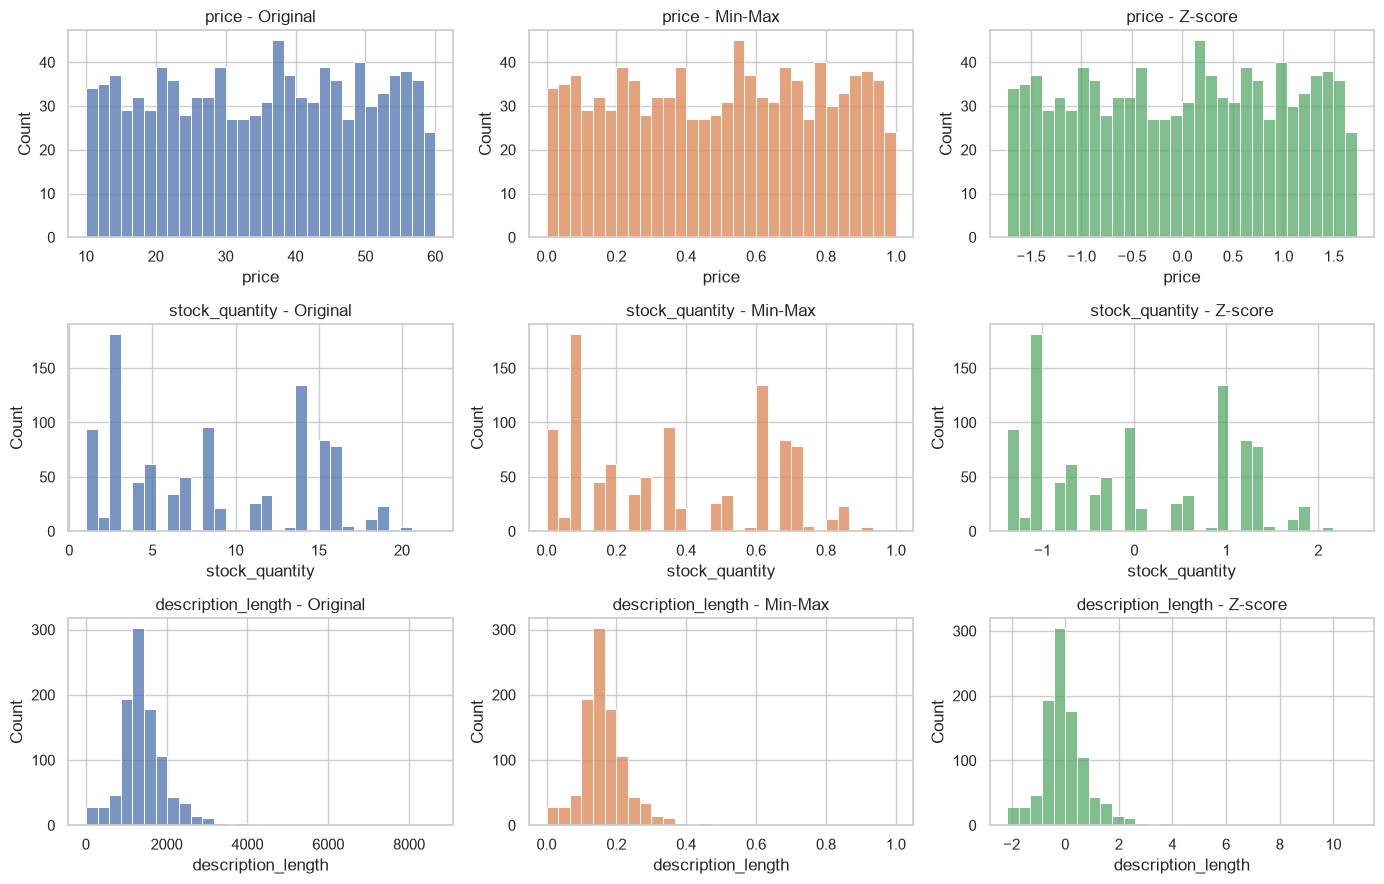

In [20]:
scale_cols = ["price", "stock_quantity", "description_length"]
X = df_imputed[scale_cols].astype(float)

minmax = MinMaxScaler()
standard = StandardScaler()
X_minmax = pd.DataFrame(minmax.fit_transform(X), columns=scale_cols, index=X.index)
X_standard = pd.DataFrame(standard.fit_transform(X), columns=scale_cols, index=X.index)

summary = pd.concat({
    "Original": X.describe().T[["mean", "std", "min", "max"]],
    "Min-Max": X_minmax.describe().T[["mean", "std", "min", "max"]],
    "Z-score": X_standard.describe().T[["mean", "std", "min", "max"]],
}, axis=1).round(3)
display(summary)

fig, axes = plt.subplots(len(scale_cols), 3, figsize=(14, 3 * len(scale_cols)))
for i, col in enumerate(scale_cols):
    for j, (data, name) in enumerate([(X, "Original"), (X_minmax, "Min-Max"), (X_standard, "Z-score")]):
        sns.histplot(data[col], bins=30, ax=axes[i, j], color=sns.color_palette()[j])
        axes[i, j].set_title(f"{col} - {name}")
plt.tight_layout()
plt.show()

**What was performed:** Applied **Min-Max normalisation** (rescales to the range 0-1) and **Z-score standardisation** (`StandardScaler`: mean 0, standard deviation 1) to the numerical features `price`, `stock_quantity` and `description_length`, and compared original and scaled distributions.

**Why:** Features are on very different scales (price about 10-60, stock about 1-22, description length in hundreds of characters). Distance-based and gradient-based algorithms (KNN, SVM, linear/ridge regression, logistic regression, neural networks) are sensitive to scale, while tree-based models (Decision Tree, Random Forest, Gradient Boosting) are not.

**What the output shows:**  Min-Max columns have min = 0 and max = 1; Z-score columns have mean about 0 and std about 1; the histograms keep the same *shape* and only the axis scale changes.

**Observation** Scaling does not fix skewness (Section 6 does). Min-Max is sensitive to outliers; Z-score is preferable for linear/KNN models. In modelling, the scaler is fitted on the training split only.

## Section 5: Exploratory Data Analysis (EDA)

In [21]:
EDA_NUM = ["price", "stock_quantity", "description_length", "star_rating"]
display(df[EDA_NUM].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
price,1000.0,35.07,14.45,10.0,22.11,35.98,47.46,59.99
stock_quantity,1000.0,8.59,5.65,1.0,3.00,7.00,14.00,22.00
description_length,1000.0,1441.45,676.50,0.0,1074.75,1353.50,1696.50,8646.00
star_rating,1000.0,2.92,1.43,1.0,2.00,3.00,4.00,5.00


**What was performed:** Selected the informative numerical variables for EDA (`price`, `stock_quantity`, `description_length`, `star_rating`) and printed their summary statistics. Constant columns (`tax`, `number_of_reviews`) are left out because they cannot show patterns.

**Why:** Summary statistics give the numbers that the following plots must support.

**What the output shows:** Mean, median (50%), min and max of each variable.

**Observation**Compare mean and median of each variable (large differences hint at skewness).

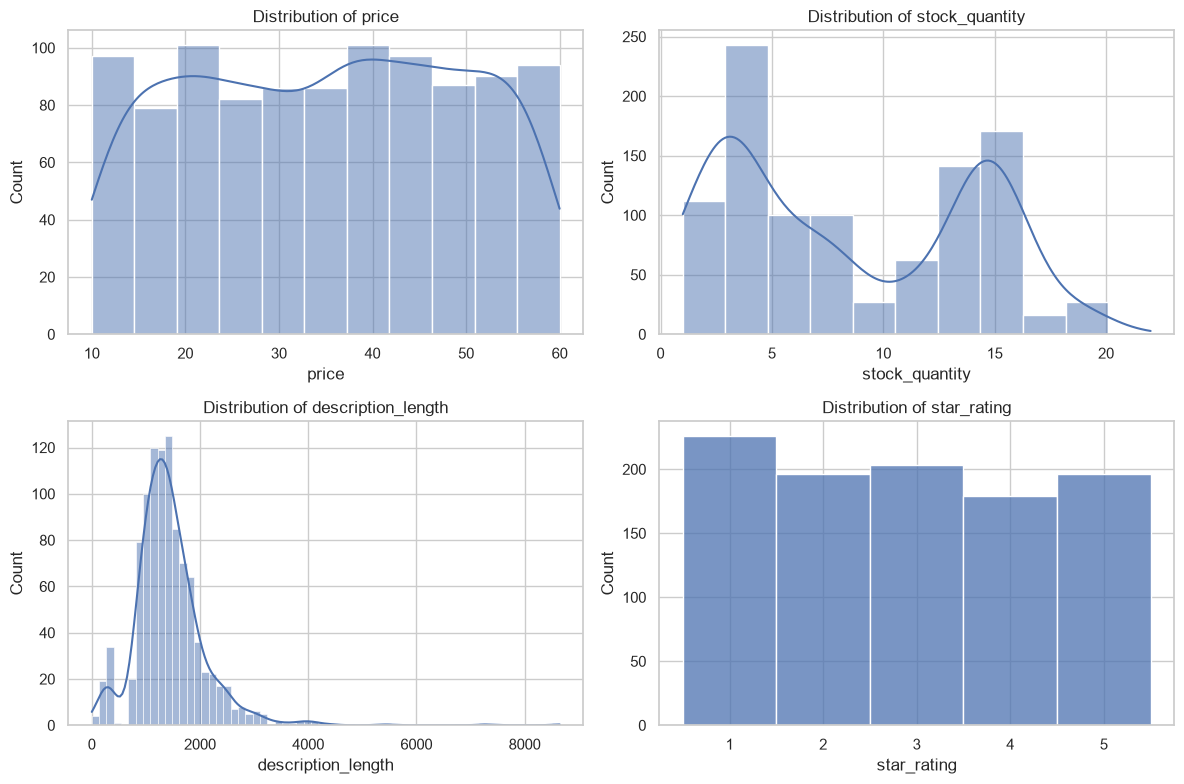

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), EDA_NUM):
    sns.histplot(df[col], kde=(col != "star_rating"), discrete=(col == "star_rating"), ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

**What was performed:** Plotted histograms (with a density curve for continuous variables) of the numerical features.

**Why:** Histograms show the shape of each distribution: symmetric, skewed, uniform or multi-modal.

**What the output shows:**  Describe each shape: for example, price spread evenly between about 10 and 60 (practice-site generated values); stock concentrated at certain values; description length right-skewed with a long tail; ratings roughly equal across 1-5.

**Observation** Which variables are roughly symmetric and which are skewed?

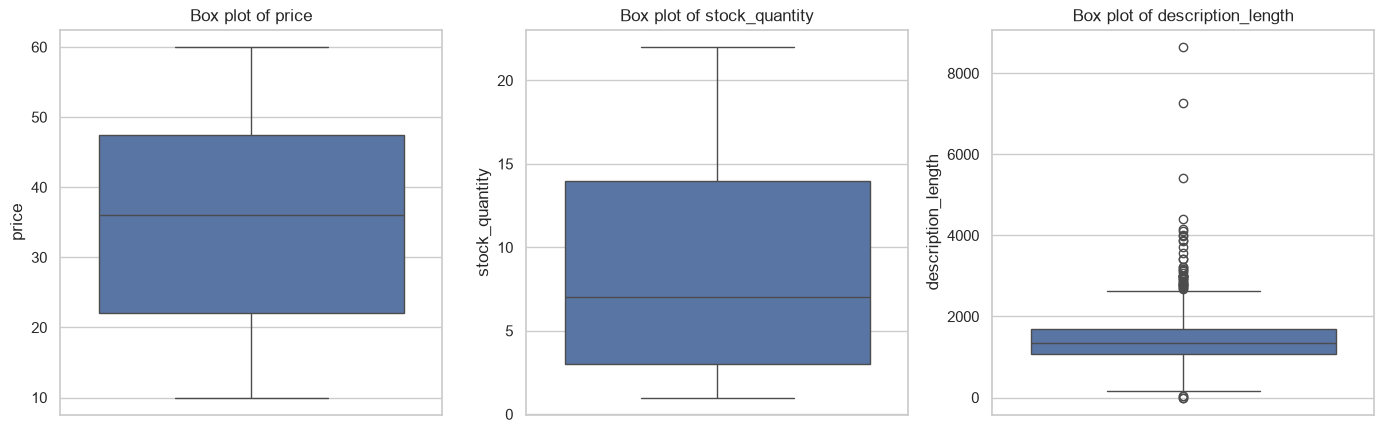

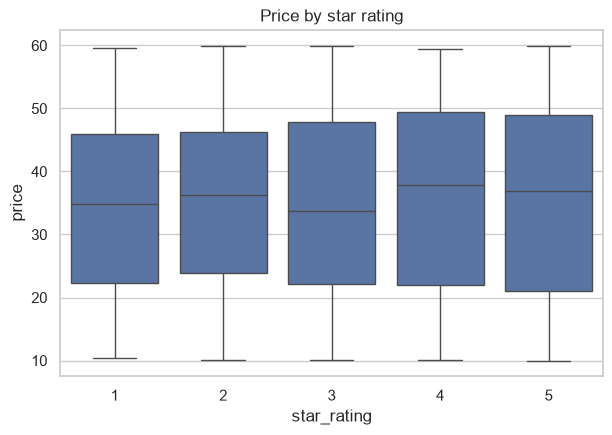

In [23]:
OUT_FEATURES = ["price", "stock_quantity", "description_length"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, col in zip(axes, OUT_FEATURES):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"Box plot of {col}")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4.5))
sns.boxplot(data=df, x="star_rating", y="price")
plt.title("Price by star rating")
plt.show()

**What was performed:** Drew box plots of the numerical features and a box plot of price for each star rating.

**Why:** Box plots show the median, quartiles and points beyond the whiskers (potential outliers); grouping by rating shows whether price differs between rating levels.

**What the output shows:**  Which variables have points beyond the whiskers; whether the price boxes for different ratings look similar.

**Observation** These are only *potential* outliers. If the price boxes look the same for every rating, price and rating are weakly related.

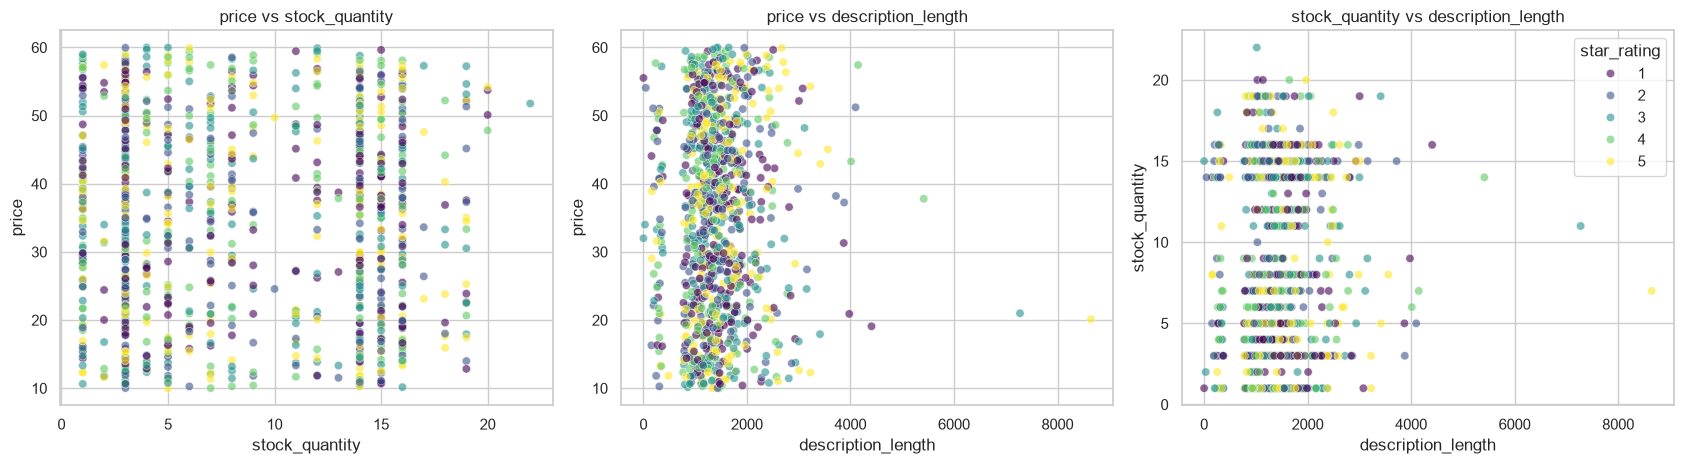

In [24]:
pairs = [("stock_quantity", "price"), ("description_length", "price"), ("description_length", "stock_quantity")]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (x, y) in zip(axes, pairs):
    sns.scatterplot(data=df, x=x, y=y, hue="star_rating", palette="viridis", alpha=0.6, ax=ax,
                    legend=(ax is axes[-1]))
    ax.set_title(f"{y} vs {x}")
plt.tight_layout()
plt.show()

**What was performed:** Created scatter plots of pairs of numerical features, coloured by star rating.

**Why:** Scatter plots reveal trends, clusters or no relationship between two features.

**What the output shows:**  Whether the points form a pattern or a shapeless cloud for price vs stock, price vs description length and stock vs description length.

**Observation** A shapeless cloud means a weak relationship. The brief warns that the site's values are generated, so weak relationships are expected and must be reported honestly.

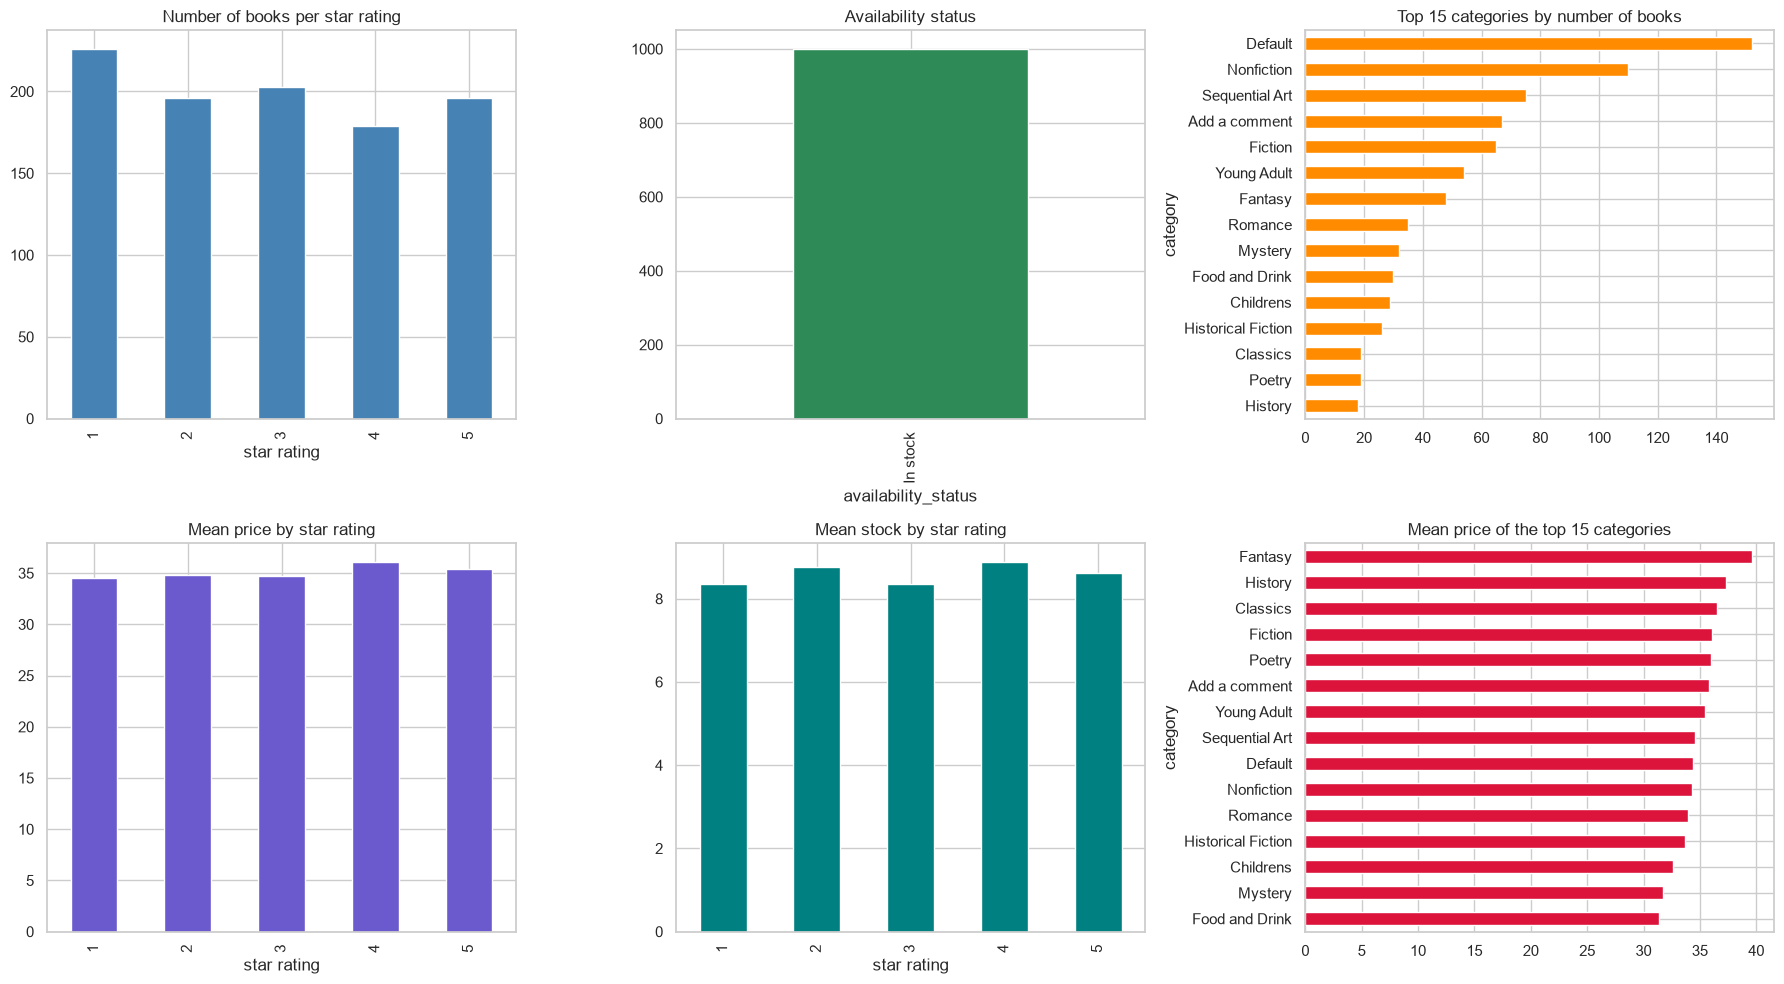

In [25]:
top_cats = df["category"].value_counts().head(15)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

df["star_rating"].value_counts().sort_index().plot.bar(ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Number of books per star rating"); axes[0, 0].set_xlabel("star rating")

df["availability_status"].value_counts(dropna=False).plot.bar(ax=axes[0, 1], color="seagreen")
axes[0, 1].set_title("Availability status")

top_cats.sort_values().plot.barh(ax=axes[0, 2], color="darkorange")
axes[0, 2].set_title("Top 15 categories by number of books")

df.groupby("star_rating")["price"].mean().plot.bar(ax=axes[1, 0], color="slateblue")
axes[1, 0].set_title("Mean price by star rating"); axes[1, 0].set_xlabel("star rating")

df.groupby("star_rating")["stock_quantity"].mean().plot.bar(ax=axes[1, 1], color="teal")
axes[1, 1].set_title("Mean stock by star rating"); axes[1, 1].set_xlabel("star rating")

df[df["category"].isin(top_cats.index)].groupby("category")["price"].mean().sort_values().plot.barh(ax=axes[1, 2], color="crimson")
axes[1, 2].set_title("Mean price of the top 15 categories")
plt.tight_layout()
plt.show()

**What was performed:** Drew bar charts comparing rating groups, availability, the 15 largest categories, and the mean price/stock per rating and per category.

**Why:** Bar charts compare groups: class balance of ratings (needed for classification), the dominance of a few categories, and whether average price differs between groups.

**What the output shows:**  The most and least common ratings; whether availability has a single value; the largest categories; whether mean price differs noticeably between ratings or categories.

**Observation**  Differences between group means that are small relative to the spread of prices may be due to chance (a hypothesis test such as ANOVA/Kruskal-Wallis can check this if chosen as an advanced technique).

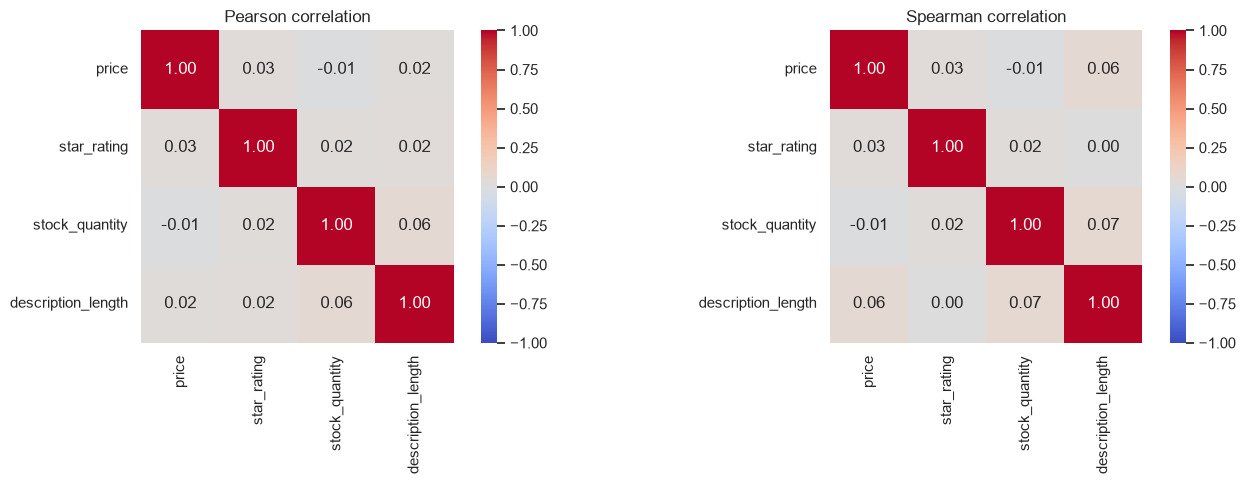

In [26]:
corr_cols = ["price", "star_rating", "stock_quantity", "description_length"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(df[corr_cols].corr(method=method), annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, square=True, ax=ax)
    ax.set_title(f"{method.capitalize()} correlation")
plt.tight_layout()
plt.show()

**What was performed:** Plotted correlation heatmaps (Pearson for linear and Spearman for rank/monotonic relationships) for the informative numerical variables. Constant columns and duplicated price columns are excluded because their correlation is undefined or trivially 1.

**Why:** Correlations show which features move together and give a first idea of which inputs may help predict price or rating.

**What the output shows:**  The strongest absolute correlation and its value; whether all correlations with `price` and `star_rating` are close to 0.

**Observation** If all correlations are near 0, the features carry little linear information about the targets, so modelling performance is expected to be weak. This is a limitation of the generated dataset and is reported honestly.

## Section 6: Skewness Analysis and Treatment

,skewness,kurtosis,mean,median,interpretation
price,-0.038,-1.210,35.07,35.98,Approximately symmetric
stock_quantity,0.212,-1.450,8.59,7.00,Approximately symmetric
description_length,2.684,20.249,1441.45,1353.50,Highly positive
star_rating,0.074,-1.318,2.92,3.00,Approximately symmetric


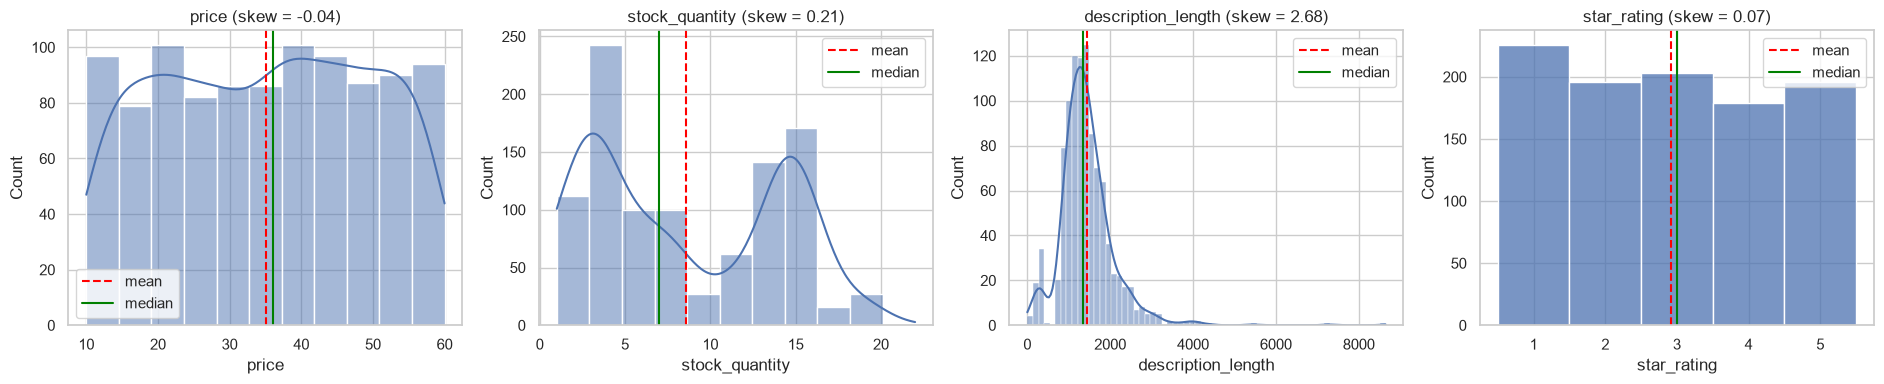

In [27]:
skew_features = ["price", "stock_quantity", "description_length", "star_rating"]

def skew_label(s):
    if s > 1: return "Highly positive"
    if s > 0.5: return "Moderately positive"
    if s < -1: return "Highly negative"
    if s < -0.5: return "Moderately negative"
    return "Approximately symmetric"

skew_table = pd.DataFrame({
    "skewness": df[skew_features].skew().round(3),
    "kurtosis": df[skew_features].kurt().round(3),
    "mean": df[skew_features].mean().round(2),
    "median": df[skew_features].median().round(2),
})
skew_table["interpretation"] = skew_table["skewness"].apply(skew_label)
display(skew_table)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, col in zip(axes, skew_features):
    sns.histplot(df[col], kde=(col != "star_rating"), discrete=(col == "star_rating"), ax=ax)
    ax.axvline(df[col].mean(), color="red", linestyle="--", label="mean")
    ax.axvline(df[col].median(), color="green", linestyle="-", label="median")
    ax.set_title(f"{col} (skew = {df[col].skew():.2f})")
    ax.legend()
plt.tight_layout()
plt.show()

**What was performed:** Calculated skewness (and kurtosis) of the numerical features, labelled each as positively skewed, negatively skewed or approximately symmetric (|skew| < 0.5 symmetric, 0.5-1 moderate, > 1 high), and plotted histograms with mean and median lines.

**Why:** Skewed features can hurt linear models and distance-based methods. Positive skew means a long right tail (mean > median); negative skew means a long left tail (mean < median).

**What the output shows:**  Skewness value and label of each feature; which are positively skewed and which (if any) are negatively skewed; relation of mean and median.

**Observation** Identify the feature(s) with |skew| > 1. `star_rating` is a discrete ordinal 1-5 and is not transformed.

,feature,skew_before,action,skew_after,improved
0,price,-0.038,kept as is (|skew| <= 1),NaN,NaN
1,stock_quantity,0.212,kept as is (|skew| <= 1),NaN,NaN
2,description_length,2.684,log1p applied,-4.267,False


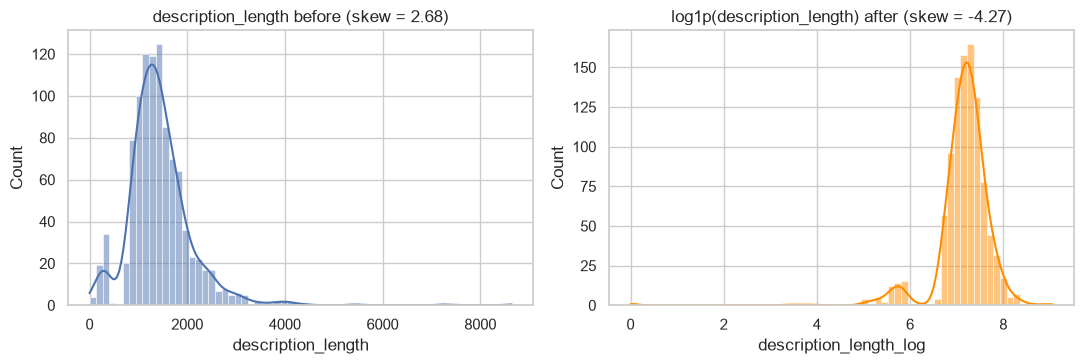

In [28]:
SKEW_THRESHOLD = 1.0                      # transform only clearly skewed features
transform_candidates = ["price", "stock_quantity", "description_length"]
skew_before = df[transform_candidates].skew()
to_transform = [c for c in transform_candidates if skew_before[c] > SKEW_THRESHOLD]

df_clean = df.copy()                      # df_clean collects transformed / treated columns
rows = []
for col in transform_candidates:
    if col in to_transform:
        df_clean[col + "_log"] = np.log1p(df[col])      # log(1 + x): safe for zeros
        after = df_clean[col + "_log"].skew()
        rows.append({"feature": col, "skew_before": round(skew_before[col], 3), "action": "log1p applied",
                     "skew_after": round(after, 3), "improved": abs(after) < abs(skew_before[col])})
    else:
        rows.append({"feature": col, "skew_before": round(skew_before[col], 3), "action": "kept as is (|skew| <= 1)",
                     "skew_after": np.nan, "improved": np.nan})
display(pd.DataFrame(rows))

if to_transform:
    fig, axes = plt.subplots(len(to_transform), 2, figsize=(11, 3.8 * len(to_transform)), squeeze=False)
    for i, col in enumerate(to_transform):
        sns.histplot(df[col], kde=True, ax=axes[i, 0]); axes[i, 0].set_title(f"{col} before (skew = {skew_before[col]:.2f})")
        sns.histplot(df_clean[col + "_log"], kde=True, ax=axes[i, 1], color="darkorange")
        axes[i, 1].set_title(f"log1p({col}) after (skew = {df_clean[col + '_log'].skew():.2f})")
    plt.tight_layout(); plt.show()
else:
    print("No feature exceeded the skewness threshold, so no transformation was applied.")

What was performed: Applied log(1 + x) transformation to features with skewness above 1 and compared distributions before and after.

Why: Log transformation reduces right skewness and improves highly skewed distributions.

Output: Shows before/after skewness, histograms, and improvement status.

Conclusion: Transformation is beneficial if skewness moves closer to 0. Features with low skewness were left unchanged to avoid unnecessary transformations.

## Section 7: Outlier Detection and Analysis

In [29]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

iqr_flags = pd.DataFrame(index=df.index)
iqr_rows = []
for col in OUT_FEATURES:
    lo, hi = iqr_bounds(df[col])
    iqr_flags[col] = (df[col] < lo) | (df[col] > hi)
    iqr_rows.append({"feature": col, "lower_fence": round(lo, 2), "upper_fence": round(hi, 2),
                     "outliers_IQR": int(iqr_flags[col].sum())})
display(pd.DataFrame(iqr_rows))

,feature,lower_fence,upper_fence,outliers_IQR
0,price,-15.92,85.48,0
1,stock_quantity,-13.50,30.50,0
2,description_length,142.12,2629.12,43


**What was performed:** Method 1, the **IQR rule**: a value is a potential outlier if it lies below Q1 - 1.5xIQR or above Q3 + 1.5xIQR.

**Why:** It is distribution-free, robust to extremes and the same rule that box plots use, so it matches Section 5.

**What the output shows:** Fences and number of flagged values for each feature.

**Observation**Which features have IQR outliers (typically only the right-skewed `description_length`)?

In [30]:
z_flags = pd.DataFrame(index=df.index)
z_rows = []
for col in OUT_FEATURES:
    z = stats.zscore(df[col].astype(float))
    z_flags[col] = np.abs(z) > 3
    z_rows.append({"feature": col, "max_abs_z": round(float(np.nanmax(np.abs(z))), 2),
                   "outliers_Zscore": int(z_flags[col].sum())})
display(pd.DataFrame(z_rows))


X_iso = StandardScaler().fit_transform(df[OUT_FEATURES].astype(float))
iso = IsolationForest(n_estimators=200, contamination=0.05, random_state=RANDOM_STATE)
iso_flag = pd.Series(iso.fit_predict(X_iso) == -1, index=df.index)
print("Isolation Forest flagged rows (contamination = 5%):", int(iso_flag.sum()))

,feature,max_abs_z,outliers_Zscore
0,price,1.74,0
1,stock_quantity,2.37,0
2,description_length,10.66,12


Isolation Forest flagged rows (contamination = 5%): 50


Methods: Z-score (flags values where |z| > 3) and Isolation Forest (contamination=0.05), which detects unusual combinations across all three features.

Why: Two methods are required. Z-score is univariate, while Isolation Forest is multivariate, allowing comparison.

Output: Shows Z-score outliers per feature, maximum |z|, and Isolation Forest flagged rows.

Conclusion: Z-score may flag fewer outliers in skewed data, while Isolation Forest flags approximately 5% by assumption. Their flagged rows may differ.

In [31]:
comparison = pd.DataFrame({
    "IQR (any feature)": iqr_flags.any(axis=1),
    "Z-score (any feature)": z_flags.any(axis=1),
    "Isolation Forest": iso_flag,
})
comparison["methods_flagging"] = comparison.sum(axis=1)

print("Rows flagged by each method:")
print(comparison.drop(columns="methods_flagging").sum())
print("\nNumber of rows flagged by 0, 1, 2 or 3 methods:")
print(comparison["methods_flagging"].value_counts().sort_index())

per_feature = pd.DataFrame({
    "IQR": iqr_flags.sum(), "Z-score": z_flags.sum(), "flagged by both": (iqr_flags & z_flags).sum(),
})
display(per_feature)

flagged = df.loc[comparison["methods_flagging"] >= 2, ["title", "price", "stock_quantity", "description_length"]]
flagged = flagged.join(comparison)
print(f"\nRows flagged by at least two methods: {len(flagged)}")
display(flagged.head(15))

Rows flagged by each method:
IQR (any feature)        43
Z-score (any feature)    12
Isolation Forest         50
dtype: int64

Number of rows flagged by 0, 1, 2 or 3 methods:
methods_flagging
0    938
1     31
2     19
3     12
Name: count, dtype: int64


,IQR,Z-score,flagged by both
price,0,0,0
stock_quantity,0,0,0
description_length,43,12,12



Rows flagged by at least two methods: 31


,title,price,stock_quantity,description_length,IQR (any feature),Z-score (any feature),Isolation Forest,methods_flagging
7,"The Coming Woman: A Novel Based on the Life of the Infamous Feminist, Victor...",17.93,19,3411,True,False,True,2
9,The Black Maria,52.15,19,3005,True,False,True,2
55,The Torch Is Passed: A Harding Family Story,19.09,16,4406,True,True,True,3
138,The Third Wave: An Entrepreneurâs Vision of the Future,12.61,15,3007,True,False,True,2
146,The Omnivore's Dilemma: A Natural History of Four Meals,38.21,15,3719,True,True,True,3
205,Becoming Wise: An Inquiry into the Mystery and Art of Living,27.43,15,3159,True,False,True,2
240,The Power of Habit: Why We Do What We Do in Life and Business,16.88,14,3001,True,False,True,2
312,"Eat Fat, Get Thin",54.07,14,45,True,False,True,2
330,Buying In: The Secret Dialogue Between What We Buy and Who We Are,37.80,14,5415,True,True,True,3
342,Abstract City,56.37,14,2751,True,False,True,2


What was performed: Compared all three methods, their overlap, and rows flagged by at least two methods.

Why: Agreement between methods increases confidence that an outlier is unusual.

Output: Shows outlier counts, overlaps, and flagged book details.

Conclusion: Identify which feature has the most outliers and whether the three methods agree.

In [32]:
print("Valid range check (min / max of each feature):")
display(df[OUT_FEATURES].agg(["min", "max"]).T)

print("Price outside the plausible range (<= 0)         :", int((df["price"] <= 0).sum()))
print("Stock outside the plausible range (< 0)          :", int((df["stock_quantity"] < 0).sum()))
print("Books with empty description (length = 0)        :", int((df["description_length"] == 0).sum()))

longest = df.nlargest(3, "description_length")
for _, r in longest.iterrows():
    print(f"\n{r['title']} -> {int(r['description_length'])} characters")
    print("   ends with:", str(r["description"])[-120:])

Valid range check (min / max of each feature):


,min,max
price,10.0,59.99
stock_quantity,1.0,22.00
description_length,0.0,8646.00


Price outside the plausible range (<= 0)         : 0
Stock outside the plausible range (< 0)          : 0
Books with empty description (length = 0)        : 2

Team of Rivals: The Political Genius of Abraham Lincoln -> 8646 characters
   ends with: istrator, he eventually concluded that the president was an unmatched leader, "very near being a 'perfect man.'" ...more

The Art of Startup Fundraising -> 7275 characters
   ends with: ndraisingâ is essential reading for entrepreneurs everywhere.â - Allen Taylor, Managing Director at Endeavor ...more

Buying In: The Secret Dialogue Between What We Buy and Who We Are -> 5415 characters
   ends with: eligion of consumption. Love his column, couldnât put his book down.ââPaco Underhill, author of Why We Buy ...more


What was performed: Checked flagged values against valid ranges and inspected the longest book descriptions.

Why: To distinguish genuine outliers from data errors.

Output: Shows feature ranges, impossible values, and description checks.

Conclusion: Values are within valid ranges, and long descriptions contain genuine text. Therefore, these are genuine outliers, not data errors.

,feature,flagged_by_IQR,decision
0,price,0,retain
1,stock_quantity,0,retain
2,description_length,43,cap


Rows before / after treatment: 1000 / 1000


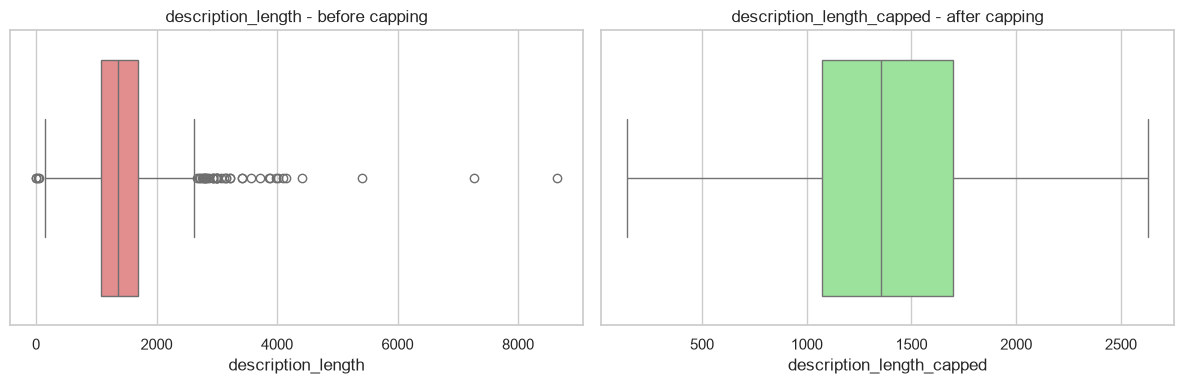

before     after
description_length mean  1441.449  1407.368
                   std    676.500   535.390
                   max   8646.000  2629.125
                   skew     2.684     0.273

In [33]:
OUTLIER_DECISION = {"price": "retain", "stock_quantity": "retain", "description_length": "cap"}

rows_to_drop = pd.Index([])
decision_rows = []
for col, decision in OUTLIER_DECISION.items():
    lo, hi = iqr_bounds(df[col])
    n_flag = int(((df[col] < lo) | (df[col] > hi)).sum())
    if decision == "cap":
        df_clean[col + "_capped"] = df[col].clip(lower=lo, upper=hi)
    elif decision == "remove":
        rows_to_drop = rows_to_drop.union(df.index[(df[col] < lo) | (df[col] > hi)])
    decision_rows.append({"feature": col, "flagged_by_IQR": n_flag, "decision": decision})
display(pd.DataFrame(decision_rows))

df_clean = df_clean.drop(index=rows_to_drop)
print("Rows before / after treatment:", len(df), "/", len(df_clean))

capped = [c + "_capped" for c, d in OUTLIER_DECISION.items() if d == "cap"]
if capped:
    fig, axes = plt.subplots(len(capped), 2, figsize=(12, 4 * len(capped)), squeeze=False)
    for i, c in enumerate(capped):
        orig = c.replace("_capped", "")
        sns.boxplot(x=df[orig], ax=axes[i, 0], color="lightcoral"); axes[i, 0].set_title(f"{orig} - before capping")
        sns.boxplot(x=df_clean[c], ax=axes[i, 1], color="lightgreen"); axes[i, 1].set_title(f"{c} - after capping")
    plt.tight_layout(); plt.show()
    stat_cmp = pd.DataFrame({
        "before": df[[c.replace('_capped', '') for c in capped]].agg(["mean", "std", "max", "skew"]).T.stack(),
    })
    after = df_clean[capped].agg(["mean", "std", "max", "skew"]).T.stack()
    after.index = stat_cmp.index
    stat_cmp["after"] = after
    display(stat_cmp.round(3))
else:
    print("No feature was capped.")

What was performed: Retained price and stock_quantity and capped extreme description_length values using the IQR upper fence.

Why: Retaining valid data avoids losing records, while capping reduces the influence of extreme values.

Output: Shows before/after box plots, statistics, capped values, and unchanged row count.

Conclusion: Genuine values were retained, description lengths were capped, and original data was preserved in a separate column.